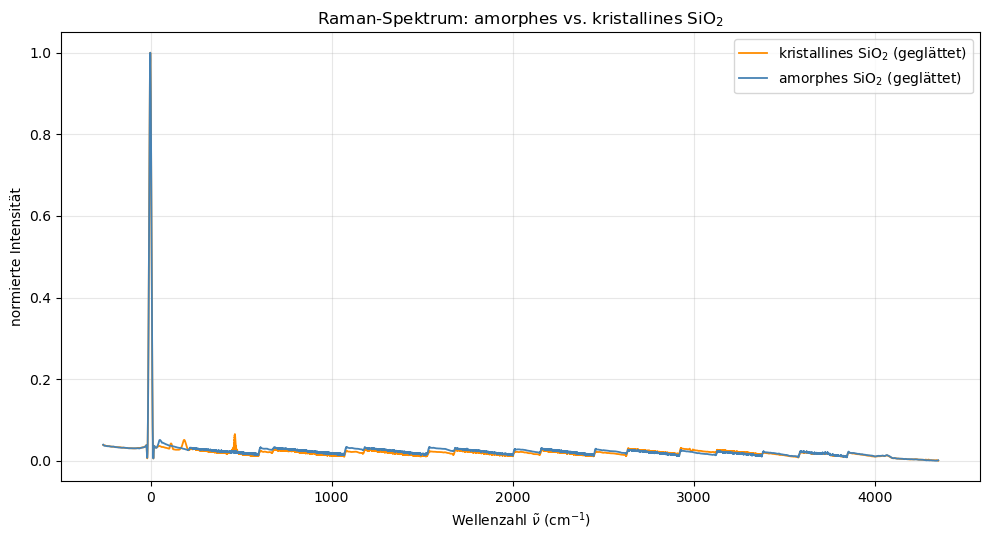

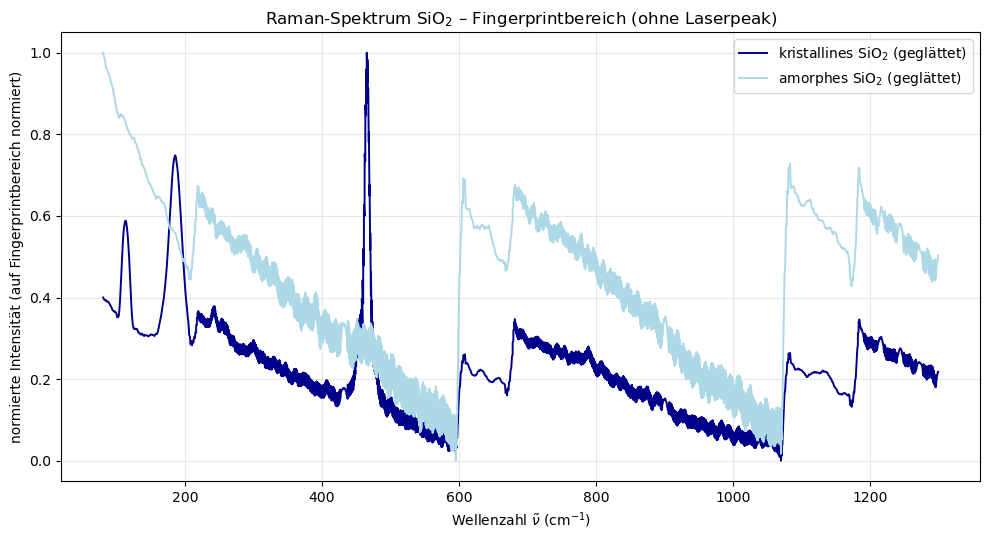

Plots gespeichert: sio2_vergleich_amorph_kristallin.png, sio2_vergleich_fingerprint.png


In [11]:
"""
Vergleich Raman-Spektren: amorphes vs. kristallines SiO2
Daten liegen als mehrere (x,y)-Spaltenpaare pro Zeile vor (zusammengesetzte Gitterfenster).
Wird eingelesen, zu einem (x,y)-Array zusammengefasst, nach Wellenzahl sortiert und geglättet.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

def lade_spektrum(dateiname):
    """Liest eine Datei mit mehreren (x,y)-Spaltenpaaren pro Zeile ein
    und gibt zwei sortierte, eindimensionale Arrays (Wellenzahl, Intensität) zurück."""
    x_liste, y_liste = [], []
    with open(dateiname, "r", encoding="utf-8") as f:
        for zeile in f:
            zeile = zeile.strip()
            if not zeile:
                continue
            werte = zeile.replace(",", ".").split("\t")
            # jeweils zwei Spalten (x,y) zusammenfassen
            for i in range(0, len(werte) - 1, 2):
                x_liste.append(float(werte[i]))
                y_liste.append(float(werte[i + 1]))

    x = np.array(x_liste)
    y = np.array(y_liste)
    sortier_idx = np.argsort(x)
    return x[sortier_idx], y[sortier_idx]

def glaetten(y, fenster=21, ordnung=3):
    return savgol_filter(y, fenster, ordnung)

def normieren(y):
    return (y - y.min()) / (y.max() - y.min())

# ---------- Daten laden ----------
wz_amorph, int_amorph = lade_spektrum("amorph_30.txt")
wz_kristallin, int_kristallin = lade_spektrum("kristallin 30.txt")

int_amorph_glatt = glaetten(int_amorph)
int_kristallin_glatt = glaetten(int_kristallin)

# ---------- Fingerprintbereich: dominanten Rayleigh-/Laserpeak bei 0 cm^-1 ausblenden ----------
# Bereich grob zwischen 80 cm^-1 und 1300 cm^-1, dort liegen die charakteristischen SiO2-Banden
# (z.B. Quarz: scharfer A1-Mode bei ~465 cm^-1; amorphes SiO2: breiter "Boson-Peak"/D2-Bande ~440-490 cm^-1)
def fenstere(x, y, x_min=80, x_max=1300):
    maske = (x > x_min) & (x < x_max)
    return x[maske], y[maske]

wz_a_fp, int_a_fp = fenstere(wz_amorph, int_amorph_glatt)
wz_k_fp, int_k_fp = fenstere(wz_kristallin, int_kristallin_glatt)

# auf den Fingerprintbereich normieren, damit beide Spektren dort direkt vergleichbar sind
int_a_fp_norm = normieren(int_a_fp)
int_k_fp_norm = normieren(int_k_fp)

# auf [0,1] normieren (gesamter Bereich, inkl. Laserpeak) für die Übersicht
int_amorph_norm = normieren(int_amorph_glatt)
int_kristallin_norm = normieren(int_kristallin_glatt)

# ---------- Plot: Übereinanderlegung amorph vs. kristallin ----------
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(wz_kristallin, int_kristallin_norm, lw=1.3, color="darkorange",
        label="kristallines SiO$_2$ (geglättet)")
ax.plot(wz_amorph, int_amorph_norm, lw=1.3, color="steelblue",
        label="amorphes SiO$_2$ (geglättet)")

ax.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax.set_ylabel("normierte Intensität")
ax.set_title("Raman-Spektrum: amorphes vs. kristallines SiO$_2$")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("sio2_vergleich_amorph_kristallin.png", dpi=200)

# ---------- Zusatzplot: Fingerprintbereich ohne den dominanten Laserpeak ----------
fig2, ax2 = plt.subplots(figsize=(10, 5.5))
ax2.plot(wz_k_fp, int_k_fp_norm, lw=1.4, color="darkblue",
         label="kristallines SiO$_2$ (geglättet)")
ax2.plot(wz_a_fp, int_a_fp_norm, lw=1.4, color="lightblue",
         label="amorphes SiO$_2$ (geglättet)")
ax2.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax2.set_ylabel("normierte Intensität (auf Fingerprintbereich normiert)")
ax2.set_title("Raman-Spektrum SiO$_2$ – Fingerprintbereich (ohne Laserpeak)")
ax2.legend()
ax2.grid(alpha=0.3)
fig2.tight_layout()
fig2.savefig("sio2_vergleich_fingerprint.png", dpi=200)

plt.show()
print("Plots gespeichert: sio2_vergleich_amorph_kristallin.png, sio2_vergleich_fingerprint.png")


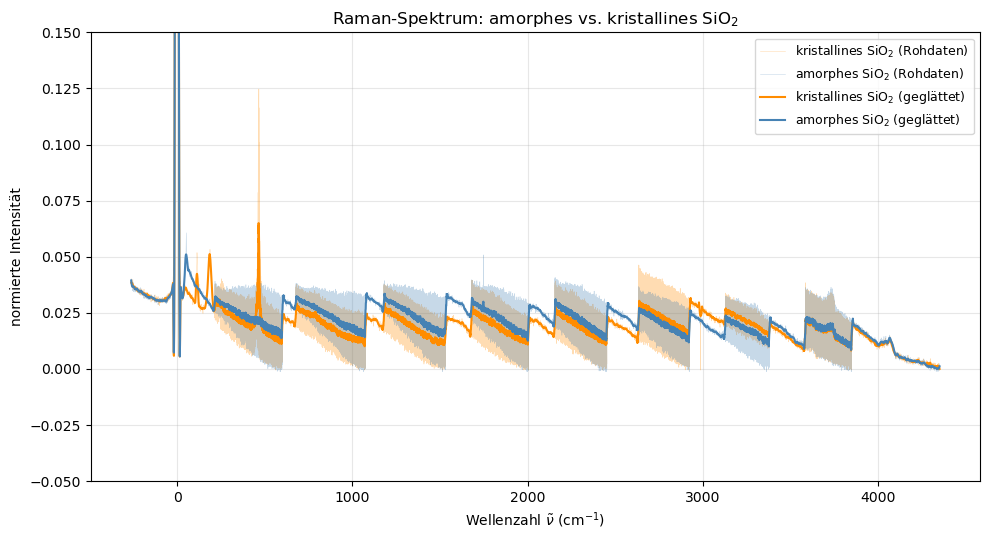

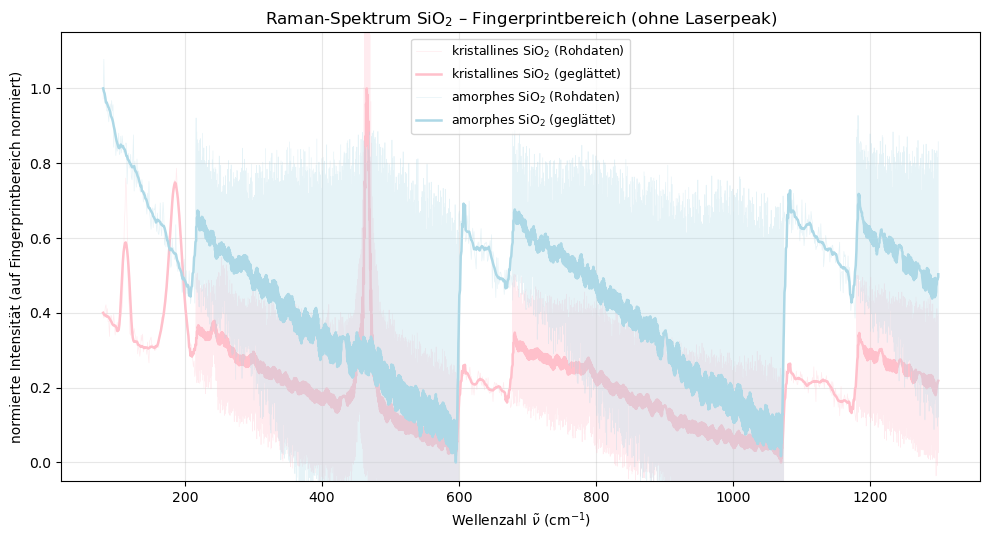

Plots gespeichert: sio2_vergleich_amorph_kristallin.png, sio2_vergleich_fingerprint.png


In [18]:
"""
Vergleich Raman-Spektren: amorphes vs. kristallines SiO2
Daten liegen als mehrere (x,y)-Spaltenpaare pro Zeile vor (zusammengesetzte Gitterfenster).
Wird eingelesen, zu einem (x,y)-Array zusammengefasst, nach Wellenzahl sortiert und geglättet.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

def lade_spektrum(dateiname):
    """Liest eine Datei mit mehreren (x,y)-Spaltenpaaren pro Zeile ein
    und gibt zwei sortierte, eindimensionale Arrays (Wellenzahl, Intensität) zurück."""
    x_liste, y_liste = [], []
    with open(dateiname, "r", encoding="utf-8") as f:
        for zeile in f:
            zeile = zeile.strip()
            if not zeile:
                continue
            werte = zeile.replace(",", ".").split("\t")
            # jeweils zwei Spalten (x,y) zusammenfassen
            for i in range(0, len(werte) - 1, 2):
                x_liste.append(float(werte[i]))
                y_liste.append(float(werte[i + 1]))

    x = np.array(x_liste)
    y = np.array(y_liste)
    sortier_idx = np.argsort(x)
    return x[sortier_idx], y[sortier_idx]

def glaetten(y, fenster=21, ordnung=3):
    return savgol_filter(y, fenster, ordnung)

def normieren(y):
    return (y - y.min()) / (y.max() - y.min())

# ---------- Daten laden ----------
wz_amorph, int_amorph = lade_spektrum("amorph_30.txt")
wz_kristallin, int_kristallin = lade_spektrum("kristallin 30.txt")

int_amorph_glatt = glaetten(int_amorph)
int_kristallin_glatt = glaetten(int_kristallin)

# ---------- Fingerprintbereich: dominanten Rayleigh-/Laserpeak bei 0 cm^-1 ausblenden ----------
# Bereich grob zwischen 80 cm^-1 und 1300 cm^-1, dort liegen die charakteristischen SiO2-Banden
# (z.B. Quarz: scharfer A1-Mode bei ~465 cm^-1; amorphes SiO2: breiter "Boson-Peak"/D2-Bande ~440-490 cm^-1)
def fenstere(x, y, x_min=80, x_max=1300):
    maske = (x > x_min) & (x < x_max)
    return x[maske], y[maske]

wz_a_fp, int_a_fp = fenstere(wz_amorph, int_amorph_glatt)
wz_k_fp, int_k_fp = fenstere(wz_kristallin, int_kristallin_glatt)

# Rohdaten (ungeglättet) auf denselben Bereich zuschneiden, zum direkten Vergleich
wz_a_fp_roh, int_a_fp_roh = fenstere(wz_amorph, int_amorph)
wz_k_fp_roh, int_k_fp_roh = fenstere(wz_kristallin, int_kristallin)

# auf den Fingerprintbereich normieren, damit beide Spektren dort direkt vergleichbar sind
int_a_fp_norm = normieren(int_a_fp)
int_k_fp_norm = normieren(int_k_fp)

# Rohdaten mit denselben Min/Max-Werten wie die geglätteten Daten normieren,
# damit beide auf derselben Skala liegen (sonst würde das Rauschen die Normierung verzerren)
int_a_fp_roh_norm = (int_a_fp_roh - int_a_fp.min()) / (int_a_fp.max() - int_a_fp.min())
int_k_fp_roh_norm = (int_k_fp_roh - int_k_fp.min()) / (int_k_fp.max() - int_k_fp.min())

# auf [0,1] normieren (gesamter Bereich, inkl. Laserpeak) für die Übersicht
int_amorph_norm = normieren(int_amorph_glatt)
int_kristallin_norm = normieren(int_kristallin_glatt)

# Rohdaten auf [0,1] normieren (gleiche Skala wie geglättete Übersichtskurven)
int_amorph_roh_norm = (int_amorph - int_amorph_glatt.min()) / (int_amorph_glatt.max() - int_amorph_glatt.min())
int_kristallin_roh_norm = (int_kristallin - int_kristallin_glatt.min()) / (int_kristallin_glatt.max() - int_kristallin_glatt.min())

# ---------- Plot: Übereinanderlegung amorph vs. kristallin ----------
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(wz_kristallin, int_kristallin_roh_norm, lw=0.4, color="darkorange", alpha=0.3, label="kristallines SiO$_2$ (Rohdaten)")
ax.plot(wz_amorph, int_amorph_roh_norm, lw=0.4, color="steelblue", alpha=0.3, label="amorphes SiO$_2$ (Rohdaten)")
ax.plot(wz_kristallin, int_kristallin_norm, lw=1.5, color="darkorange",
        label="kristallines SiO$_2$ (geglättet)")
ax.plot(wz_amorph, int_amorph_norm, lw=1.5, color="steelblue",
        label="amorphes SiO$_2$ (geglättet)")
ax.set_ylim(-0.05, 0.15)

ax.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax.set_ylabel("normierte Intensität")
ax.set_title("Raman-Spektrum: amorphes vs. kristallines SiO$_2$")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("sio2_vergleich_amorph_kristallin.png", dpi=200)

# ---------- Zusatzplot: Fingerprintbereich ohne den dominanten Laserpeak ----------
fig2, ax2 = plt.subplots(figsize=(10, 5.5))
# Rohdaten zuerst (dünn, transparent, im Hintergrund), dann geglättete Kurve darüber
ax2.plot(wz_k_fp_roh, int_k_fp_roh_norm, lw=0.5, color="pink", alpha=0.3, label="kristallines SiO$_2$ (Rohdaten)")
ax2.plot(wz_k_fp, int_k_fp_norm, lw=1.8, color="pink",
         label="kristallines SiO$_2$ (geglättet)")

ax2.plot(wz_a_fp_roh, int_a_fp_roh_norm, lw=0.5, color="lightblue", alpha=0.3, label="amorphes SiO$_2$ (Rohdaten)")
ax2.plot(wz_a_fp, int_a_fp_norm, lw=1.8, color="lightblue",
         label="amorphes SiO$_2$ (geglättet)")

ax2.set_ylim(-0.05, 1.15)
ax2.set_xlabel(r"Wellenzahl $\tilde{\nu}$ (cm$^{-1}$)")
ax2.set_ylabel("normierte Intensität (auf Fingerprintbereich normiert)")
ax2.set_title("Raman-Spektrum SiO$_2$ – Fingerprintbereich (ohne Laserpeak)")
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)
fig2.tight_layout()
fig2.savefig("sio2_vergleich_fingerprint.png", dpi=200)

plt.show()
print("Plots gespeichert: sio2_vergleich_amorph_kristallin.png, sio2_vergleich_fingerprint.png")